# EMQA_L2_lear_sel

**What LEAR keeps: yesterday's same hour and the weekday, rarely the lagged fundamentals**

Energy Markets Quantitative Analysis (EMQA), Lecture 2 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L2/EMQA_L2_lear_sel/EMQA_L2_lear_sel.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

In [2]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

# course chart style: transparent background, no grid, legend at the bottom outside the axes
plt.rcParams.update({
    "figure.facecolor": "none", "axes.facecolor": "none", "savefig.transparent": True,
    "axes.grid": False, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#222222", "axes.labelcolor": "#222222", "xtick.color": "#222222", "ytick.color": "#222222",
    "text.color": "#222222", "font.size": 11, "axes.titlesize": 11.5, "axes.labelsize": 11,
    "legend.fontsize": 10.5, "legend.frameon": False, "lines.linewidth": 1.4, "font.family": "DejaVu Sans"})
PAL = {"RO": "#2a78d6", "DE_LU": "#eb6834", "HU": "#1baf7a", "BG": "#eda100",
       "c5": "#e87ba4", "c6": "#008300", "c7": "#6250d6", "c8": "#e34948"}   # fixed colour per entity


def legend_bottom(fig, handles=None, labels=None, ncol=4, y=0.0):
    """Legend centred under the axes, outside the plotting area."""
    if handles is None:
        handles, labels = [], []
        for ax in fig.axes:
            for hh, ll in zip(*ax.get_legend_handles_labels()):
                if ll not in labels:
                    handles.append(hh)
                    labels.append(ll)
    if handles:
        fig.legend(handles, labels, loc="lower center", ncol=ncol, bbox_to_anchor=(0.5, y),
                   frameon=False, handlelength=2.0, columnspacing=1.2)

## Data and cut-off

In [3]:
TZ = "Europe/Brussels"
PD = pd.read_csv(DATA + "power_da_prices_daily_cet.csv", parse_dates=["date_cet"]).set_index("date_cet")
_hydro = pd.read_csv(DATA + "generation_ro_mw_daily_cet.csv", usecols=["date_cet", "hydro_run_of_river"],
                     parse_dates=["date_cet"]).set_index("date_cet")["hydro_run_of_river"]
# cut-off = last complete month covered by the prices and the Romanian generation data
_raw_last = min(PD["RO"].dropna().index.max(), _hydro.dropna().index.max())
END = pd.Timestamp(((_raw_last + pd.Timedelta(days=1)).to_period("M").to_timestamp() - pd.Timedelta(days=1)).date())
START = pd.Timestamp("2022-01-01")
N_TEST, N_BURN = 365, 182                                  # test year; burn-in (its forecasts only feed QRA, CP, HS)
TEST0 = END - pd.Timedelta(days=N_TEST - 1)
FC0 = TEST0 - pd.Timedelta(days=N_BURN)
FDAYS = pd.date_range(FC0, END, freq="D")                  # burn-in + test days
TDAYS = pd.date_range(TEST0, END, freq="D")                # test days
print("cut-off:", END.date(), "| test year:", TEST0.date(), "to", END.date())

cut-off: 2026-10-31 | test year: 2025-11-01 to 2026-10-31


## Panels of price, load and wind + solar

In [4]:
def day_matrix(s):
    """UTC-indexed hourly series -> CET delivery day x 24 hours (Assignment 1 / epftoolbox DST convention) + DST flag."""
    s = s.copy()
    s.index = pd.to_datetime(s.index, utc=True).tz_convert(TZ)
    df = pd.DataFrame({"v": s.values, "day": s.index.tz_localize(None).normalize(), "h": s.index.hour})
    m = df.groupby(["day", "h"])["v"].mean().unstack("h").reindex(columns=range(24))     # 25-h day: doubled hour averaged
    days = m.index
    nh = ((((days + pd.Timedelta(days=1)).tz_localize(TZ)) - days.tz_localize(TZ)) / pd.Timedelta(hours=1)).astype(int)
    dst = pd.Series(np.asarray(nh != 24), index=days)
    for dd in days[dst.values]:
        if pd.isna(m.loc[dd, 2]):
            m.loc[dd, 2] = 0.5 * (m.loc[dd, 1] + m.loc[dd, 3])                              # 23-h day: h02 = mean(h01, h03)
    m = m.dropna(how="any")
    return m, dst.reindex(m.index)


HP = pd.read_csv(DATA + "power_da_prices_hourly_utc.csv", index_col=0, usecols=["timestamp_utc", "RO"])
PM, DST = day_matrix(HP["RO"].dropna())
CAL = pd.date_range(START, END, freq="D")
PM, DST = PM.reindex(CAL), DST.reindex(CAL)
GH = pd.read_csv(DATA + "generation_ro_mw_hourly_utc.csv", index_col=0, usecols=["timestamp_utc", "load", "wind_onshore", "solar"])
LM, _ = day_matrix(GH["load"].dropna())
RM, _ = day_matrix((GH["wind_onshore"] + GH["solar"]).dropna())
LM, RM = LM.reindex(CAL), RM.reindex(CAL)
assert not PM.isna().any().any() and not LM.isna().any().any() and not RM.isna().any().any(), "panel has gaps"
L_, R_ = LM.values.astype(float), RM.values.astype(float)
P_ = PM.values.astype(float)
DOW = CAL.dayofweek.values
IDX = {t: i for i, t in enumerate(CAL)}
TI_ROWS = np.array([IDX[t] for t in TDAYS])              # panel rows of the test days
A = P_[TI_ROWS]                                          # actual prices of the test year, days x 24
# naive benchmark: same hour of d-7 on Monday, Saturday, Sunday, of d-1 otherwise
NAIVE = np.array([P_[i - 7] if DOW[i] in (0, 5, 6) else P_[i - 1] for i in TI_ROWS])
print("panel:", CAL[0].date(), "to", CAL[-1].date(), len(CAL), "days x 24 hours")

panel: 2022-01-01 to 2026-10-31 1765 days x 24 hours


## LASSO selection

LEAR(728) is re-estimated every day of the test year for each hour; the LASSO keeps a regressor when its coefficient is not zero. The 247 columns are, in order: price of d-1, d-2, d-3, d-7 (24 hours each), load and wind + solar of d-2, d-3, d-7 (24 hours each), 7 day-of-week dummies. The selection computed by `lectures/L2/analysis_L2.py` is loaded from the file saved next to this notebook (`RUN_ALL = True` recomputes it, about 15 min on one core).

In [5]:
RUN_ALL = False   # True: recompute the forecasts from the data (LEAR(728) roughly 15 min on one core; joblib uses all cores)

QL = REPO + "Quantlets/L2/EMQA_L2_lear_sel/"          # saved results of this Quantlet


def load_npz(path):
    if path.startswith("http"):
        import io
        import urllib.request
        return np.load(io.BytesIO(urllib.request.urlopen(path).read()))
    return np.load(path)


def load_csv(name, days):
    S = pd.read_csv(QL + name, parse_dates=["date"], float_precision="round_trip")
    assert (pd.DatetimeIndex(S["date"].drop_duplicates()) == days).all()
    return S


from scipy import stats


def shift_rows(A, k):
    out = np.full_like(A, np.nan)
    out[k:] = A[:-k]
    return out


def mad_scale(x):
    x = np.asarray(x, float).ravel()
    m = np.median(x)
    s = stats.median_abs_deviation(x, scale="normal")
    return m, (s if s > 0 else 1.0)


PLAGS, XLAGS = (1, 2, 3, 7), (2, 3, 7)                   # price lags; lags of load and wind+solar (days)
LEAR_W = (364, 546, 728)


def lear_design(Pa, La, Ra, lo, i):
    """LEAR regressors (Assignment 1: 247 columns) for rows lo..i, with transforms fitted on rows available at gate closure."""
    m, s = mad_scale(Pa[lo - 7:i])
    mL, sL = mad_scale(La[lo - 7:i - 1])
    mR, sR = mad_scale(Ra[lo - 7:i - 1])
    rows = slice(lo, i + 1)
    blocks = [np.arcsinh((shift_rows(Pa, k)[rows] - m) / s) for k in PLAGS]
    blocks += [np.arcsinh((shift_rows(La, k)[rows] - mL) / sL) for k in XLAGS]
    blocks += [np.arcsinh((shift_rows(Ra, k)[rows] - mR) / sR) for k in XLAGS]
    blocks.append(np.eye(7)[DOW[rows]])
    X = np.column_stack(blocks)
    Y = np.arcsinh((Pa[rows] - m) / s)
    return X, Y, m, s


def lear_day(Pa, La, Ra, i, T):
    from sklearn.linear_model import LassoLarsIC
    lo = i - T
    X, Y, m, s = lear_design(Pa, La, Ra, lo, i)
    mu, sd = X[:-1].mean(0), X[:-1].std(0)
    sd[sd == 0] = 1.0
    Xs = (X - mu) / sd
    out, nz = np.zeros(24), np.zeros((24, X.shape[1]), bool)
    for h in range(24):
        mdl = LassoLarsIC(criterion="aic", max_iter=2000).fit(Xs[:-1], Y[:-1, h])
        out[h] = mdl.predict(Xs[-1:])[0]
        nz[h] = mdl.coef_ != 0
    return m + s * np.sinh(out), nz


if RUN_ALL:
    from joblib import Parallel, delayed
    _r = Parallel(n_jobs=-1)(delayed(lear_day)(P_, L_, R_, i, 728) for i in TI_ROWS)
    LEAR_NZ = np.array([r[1] for r in _r])              # days x 24 hours x 247 regressors: kept or not
else:
    LEAR_NZ = load_npz(QL + "lear_nz_test.npz")["nz"]
print("regressors kept per hour and day: mean %.1f of %d" % (LEAR_NZ.sum(2).mean(), LEAR_NZ.shape[2]))

regressors kept per hour and day: mean 42.0 of 247


In [6]:
GROUPS = {"p1_same": None, "p1_other": None, "p2": (24, 48), "p3": (48, 72), "p7": (72, 96), "load": (96, 168),
          "res": (168, 240), "dow": (240, 247)}
SEL = np.zeros((len(GROUPS), 24))
for gi, (g, rg) in enumerate(GROUPS.items()):
    for h in range(24):
        if g == "p1_same":
            SEL[gi, h] = LEAR_NZ[:, h, h].mean()
        elif g == "p1_other":
            SEL[gi, h] = LEAR_NZ[:, h, [j for j in range(24) if j != h]].mean()
        else:
            SEL[gi, h] = LEAR_NZ[:, h, rg[0]:rg[1]].mean()

## The chart

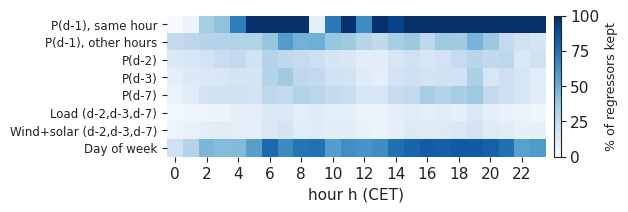

In [7]:
GLAB = ["P(d-1), same hour", "P(d-1), other hours", "P(d-2)", "P(d-3)", "P(d-7)", "Load (d-2,d-3,d-7)",
        "Wind+solar (d-2,d-3,d-7)", "Day of week"]
fig, ax = plt.subplots(figsize=(6.4, 2.3))
im = ax.imshow(SEL * 100, aspect="auto", cmap="Blues", vmin=0, vmax=100)
ax.set_yticks(range(len(GLAB)))
ax.set_yticklabels(GLAB, fontsize=8.5)
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("hour h (CET)")
cb = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02)
cb.set_label("% of regressors kept", fontsize=9)
ax.spines[:].set_visible(False)
fig.tight_layout(rect=(0, 0.02, 1, 1))
plt.savefig('lear_sel.png', dpi=150, bbox_inches='tight', transparent=True)
plt.show()

In [8]:
print("Numbers on the slide")
print(f'  kept, P(d-1) same hour, %: {SEL[0].mean() * 100:.1f}')
print(f'  kept, day of week, %: {SEL[7].mean() * 100:.1f}')
print(f'  kept, load, %: {SEL[5].mean() * 100:.1f}')
print(f'  kept, wind + solar, %: {SEL[6].mean() * 100:.1f}')
print(f'  kept, P(d-7), %: {SEL[4].mean() * 100:.1f}')
print(f'  regressors kept, mean per hour and day: {LEAR_NZ.sum(2).mean():.1f}')

Numbers on the slide
  kept, P(d-1) same hour, %: 78.8
  kept, day of week, %: 63.9
  kept, load, %: 8.6
  kept, wind + solar, %: 10.9
  kept, P(d-7), %: 22.9
  regressors kept, mean per hour and day: 42.0
